# 📦 Delivery Performance Analytics — KPI, Root Cause Analysis & Late-Risk Model
**Dataset:** Olist Brazilian E-Commerce (≈100K marketplace orders, 2016–2018) · **Stack:** SQL (SQLite → portable to PostgreSQL/MySQL), Python (pandas, statsmodels, LightGBM), BI dashboard (Power BI / Looker Studio)

> **Note on data:** Data berasal dari marketplace Brasil, bukan Indonesia/Malaysia. Yang ditunjukkan di sini adalah *metodologi* analisis operasi delivery, yang berlaku untuk marketplace manapun (termasuk model operasi seperti Shopee Express).

## Business questions
1. Seberapa baik performa delivery? (On-time rate, rata-rata hari pengiriman, % terlambat, rata-rata keterlambatan)
2. **Tahap mana yang menyebabkan keterlambatan?** Approval (platform/payment), seller handover (sisi penjual), atau carrier transit (kurir) — dan seberapa banyak yang justru karena *estimasi terlalu ketat*?
3. Di mana masalahnya terkonsentrasi? (wilayah, lane seller→customer, seller, kategori)
4. Apakah keterlambatan berasosiasi dengan review rendah, setelah dikontrol faktor lain?
5. Bisakah order berisiko telat diprediksi **saat checkout**, supaya bisa ditangani proaktif?

## What makes this different from a typical Olist notebook
| Angle | Kenapa penting |
|---|---|
| **Distance-adjusted RCA** | Transit "lama" belum tentu salah kurir, bisa karena jarak jauh. Benchmark transit dihitung dari jarak (haversine), jadi atribusi lebih adil. |
| **4 kategori penyebab, termasuk "Tight estimate"** | Order telat padahal semua tahap normal = masalah di kalibrasi estimasi, bukan operasi. |
| **Estimate calibration** | Mengecek apakah janji ke customer realistis per wilayah (terlalu ketat vs terlalu longgar). |
| **Seller Pareto + scorecard** | Konsentrasi keterlambatan sisi seller → rekomendasi yang bisa langsung ditindaklanjuti. |
| **Controlled review impact** | Regresi dengan kontrol kategori, wilayah, jarak, harga. Hasil dilaporkan sebagai asosiasi, bukan kausal. |
| **Late-risk model + SHAP (time-based split)** | Hanya fitur yang tersedia saat checkout, validasi out-of-time, dan lift analysis untuk use case bisnis. |
| **SQL dan pandas saling di-cross-check** | KPI dihitung dua kali dan harus cocok, sebagai bukti kualitas. |

## Metric definitions (dipakai konsisten di semua analisis)
- **Analysis base:** `order_status = 'delivered'` dan keempat timestamp (approved, carrier, delivered, estimated) tidak kosong dan urutan waktunya valid.
- **Late order:** tanggal diterima customer **>** tanggal estimasi (perbandingan level hari kalender, karena janji ke customer berupa tanggal).
- **Delay days:** selisih hari kalender (delivered − estimated), minimal 0.
- **Stages:** `approval = approved − purchase` · `seller handover = carrier pickup − approved` · `carrier transit = delivered − carrier pickup`.

## 1. Setup & load data

In [130]:
import os, glob, warnings, sqlite3
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import seaborn as sns
from IPython.display import display, Markdown

warnings.filterwarnings('ignore')
pd.set_option('display.max_columns', 60)
pd.set_option('display.width', 200)
pd.set_option('display.float_format', lambda x: f'{x:,.2f}')

ACCENT, GREY, BLUE, GREEN = '#EE4D2D', '#6B7280', '#2563EB', '#16A34A'
sns.set_theme(style='whitegrid', context='notebook')
plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False,
                     'axes.titleweight': 'bold', 'axes.titlesize': 12})

# --- locate the dataset (works with different Kaggle mount layouts) ---
hits = glob.glob('/kaggle/input/**/olist_orders_dataset.csv', recursive=True) \
       or glob.glob('./**/olist_orders_dataset.csv', recursive=True)
assert hits, 'Dataset not found. Add "Brazilian E-Commerce Public Dataset by Olist" via Add Input.'
DATA_DIR = os.path.dirname(hits[0])
WORK_DIR = '/kaggle/working' if os.path.exists('/kaggle/working') else '.'
FIG_DIR, OUT_DIR, SQL_DIR = (os.path.join(WORK_DIR, d) for d in ('figures', 'dashboard_data', 'sql'))
for d in (FIG_DIR, OUT_DIR, SQL_DIR):
    os.makedirs(d, exist_ok=True)

def save_fig(name):
    plt.tight_layout()
    plt.savefig(os.path.join(FIG_DIR, f'{name}.png'), dpi=160, bbox_inches='tight')
    plt.show()

RANDOM_STATE = 42
print('Data dir:', DATA_DIR)

Data dir: /kaggle/input/datasets/olistbr/brazilian-ecommerce


In [131]:
FILES = {
    'orders': 'olist_orders_dataset.csv', 'customers': 'olist_customers_dataset.csv',
    'items': 'olist_order_items_dataset.csv', 'reviews': 'olist_order_reviews_dataset.csv',
    'products': 'olist_products_dataset.csv', 'sellers': 'olist_sellers_dataset.csv',
    'geo': 'olist_geolocation_dataset.csv', 'trans': 'product_category_name_translation.csv',
}
raw = {k: pd.read_csv(os.path.join(DATA_DIR, v)) for k, v in FILES.items()}
pd.DataFrame({'table': list(raw), 'rows': [len(v) for v in raw.values()],
              'columns': [v.shape[1] for v in raw.values()]})

,table,rows,columns
0,orders,99441,8
1,customers,99441,5
2,items,112650,7
3,reviews,99224,7
4,products,32951,9
5,sellers,3095,4
6,geo,1000163,5
7,trans,71,2


## 2. Data audit
Sebelum menghitung apapun, kita cek kualitas data dan memutuskan perlakuan yang konsisten.

In [132]:
o = raw['orders']
print('Order status distribution:')
display(o['order_status'].value_counts(dropna=False).to_frame('orders').assign(pct=lambda x: 100 * x.orders / x.orders.sum()))

ts_cols = ['order_purchase_timestamp', 'order_approved_at', 'order_delivered_carrier_date',
           'order_delivered_customer_date', 'order_estimated_delivery_date']
deliv = o[o.order_status == 'delivered']
print('\nMissing timestamps among DELIVERED orders:')
display(deliv[ts_cols].isna().sum().to_frame('missing'))

print('Purchase date range:', o.order_purchase_timestamp.min(), '→', o.order_purchase_timestamp.max())
print('Duplicate order_id in orders:', o.order_id.duplicated().sum())
print('Orders with >1 review:', (raw['reviews'].groupby('order_id').size() > 1).sum())
print('Orders with >1 seller :', (raw['items'].groupby('order_id').seller_id.nunique() > 1).sum())

Order status distribution:


,orders,pct
order_status,,
delivered,96478,97.02
shipped,1107,1.11
canceled,625,0.63
unavailable,609,0.61
invoiced,314,0.32
processing,301,0.30
created,5,0.01
approved,2,0.00



Missing timestamps among DELIVERED orders:


,missing
order_purchase_timestamp,0
order_approved_at,14
order_delivered_carrier_date,2
order_delivered_customer_date,8
order_estimated_delivery_date,0


Purchase date range: 2016-09-04 21:15:19 → 2018-10-17 17:30:18
Duplicate order_id in orders: 0
Orders with >1 review: 547
Orders with >1 seller : 1278


## 3. SQL layer — KPI queries with `JOIN`, CTE, and window functions
Tabel dimuat ke SQLite in-memory agar notebook bisa jalan di Kaggle tanpa instalasi database. Query ditulis dengan SQL standar dan disimpan ke folder `sql/` untuk repo GitHub. Untuk PostgreSQL/MySQL hanya fungsi tanggal yang perlu diganti (`julianday`, `strftime`, `date()`).

In [133]:
con = sqlite3.connect(':memory:')
raw['orders'].to_sql('olist_orders', con, index=False)
raw['customers'].to_sql('olist_customers', con, index=False)
raw['items'].to_sql('olist_order_items', con, index=False)
raw['sellers'].to_sql('olist_sellers', con, index=False)
raw['products'][['product_id', 'product_category_name']].to_sql('olist_products', con, index=False)
raw['reviews'][['review_id', 'order_id', 'review_score', 'review_creation_date',
                'review_answer_timestamp']].to_sql('olist_order_reviews', con, index=False)

def run_sql(name, query):
    """Run a query and persist it as sql/<name>.sql (for the GitHub repo)."""
    with open(os.path.join(SQL_DIR, f'{name}.sql'), 'w') as f:
        f.write(query.strip() + ';\n')
    return pd.read_sql_query(query, con)

# Shared CTE: the analysis base (same rules as the pandas cleaning step later)
BASE = """
WITH base AS (
    SELECT order_id, customer_id,
           order_purchase_timestamp       AS purchase_ts,
           order_approved_at              AS approved_ts,
           order_delivered_carrier_date   AS carrier_ts,
           order_delivered_customer_date  AS delivered_ts,
           order_estimated_delivery_date  AS estimated_ts
    FROM olist_orders
    WHERE order_status = 'delivered'
      AND order_approved_at IS NOT NULL
      AND order_delivered_carrier_date IS NOT NULL
      AND order_delivered_customer_date IS NOT NULL
      AND julianday(order_approved_at)             >= julianday(order_purchase_timestamp)
      AND julianday(order_delivered_carrier_date)  >= julianday(order_approved_at)
      AND julianday(order_delivered_customer_date) >= julianday(order_delivered_carrier_date)
)
"""
LATE = "date(b.delivered_ts) > date(b.estimated_ts)"

In [134]:
# Q1 — Headline KPIs
q1 = BASE + f"""
SELECT COUNT(*)                                                             AS delivered_orders,
       ROUND(100.0 * AVG(CASE WHEN {LATE} THEN 0.0 ELSE 1.0 END), 2)        AS on_time_rate_pct,
       ROUND(100.0 * AVG(CASE WHEN {LATE} THEN 1.0 ELSE 0.0 END), 2)        AS late_rate_pct,
       ROUND(AVG(julianday(b.delivered_ts) - julianday(b.purchase_ts)), 2)  AS avg_delivery_days,
       ROUND(AVG(CASE WHEN {LATE}
                 THEN julianday(date(b.delivered_ts)) - julianday(date(b.estimated_ts)) END), 2) AS avg_delay_days_when_late
FROM base b
"""
sql_kpi = run_sql('q1_headline_kpis', q1)
sql_kpi

,delivered_orders,on_time_rate_pct,late_rate_pct,avg_delivery_days,avg_delay_days_when_late
0,95082,93.15,6.85,12.62,10.62


In [135]:
# Q2 — Monthly KPI trend (by purchase month)
q2 = BASE + f"""
SELECT strftime('%Y-%m', b.purchase_ts)                                         AS purchase_month,
       COUNT(*)                                                                 AS orders,
       ROUND(100.0 * AVG(CASE WHEN {LATE} THEN 0.0 ELSE 1.0 END), 2)            AS on_time_rate_pct,
       ROUND(AVG(julianday(b.delivered_ts) - julianday(b.purchase_ts)), 2)      AS avg_delivery_days,
       ROUND(AVG(julianday(b.carrier_ts)   - julianday(b.approved_ts)), 2)      AS avg_seller_handover_days,
       ROUND(AVG(julianday(b.delivered_ts) - julianday(b.carrier_ts)), 2)       AS avg_transit_days
FROM base b
GROUP BY 1
HAVING COUNT(*) >= 100
ORDER BY 1
"""
run_sql('q2_monthly_kpis', q2).head(24)

,purchase_month,orders,on_time_rate_pct,avg_delivery_days,avg_seller_handover_days,avg_transit_days
0,2016-10,261,99.23,19.68,12.94,5.87
1,2017-01,747,97.05,12.63,2.92,9.22
2,2017-02,1638,97.01,13.18,3.23,9.57
3,2017-03,2545,95.44,12.95,2.86,9.84
4,2017-04,2279,93.42,14.95,3.18,11.24
5,2017-05,3530,97.00,11.33,2.58,8.35
6,2017-06,3130,97.00,11.99,2.74,8.86
7,2017-07,3841,97.19,11.62,2.72,8.51
8,2017-08,4190,97.09,11.15,2.70,8.07
9,2017-09,4136,95.65,11.84,2.78,8.65


In [136]:
# Q3 — Stage decomposition per customer state (JOIN customers)
q3 = BASE + f"""
SELECT c.customer_state,
       COUNT(*)                                                                  AS orders,
       ROUND(AVG(julianday(b.approved_ts)  - julianday(b.purchase_ts)), 2)       AS approval_days,
       ROUND(AVG(julianday(b.carrier_ts)   - julianday(b.approved_ts)), 2)       AS seller_handover_days,
       ROUND(AVG(julianday(b.delivered_ts) - julianday(b.carrier_ts)), 2)        AS carrier_transit_days,
       ROUND(100.0 * AVG(CASE WHEN {LATE} THEN 1.0 ELSE 0.0 END), 2)             AS late_rate_pct
FROM base b
JOIN olist_customers c ON c.customer_id = b.customer_id
GROUP BY c.customer_state
HAVING COUNT(*) >= 100
ORDER BY late_rate_pct DESC
"""
run_sql('q3_stage_by_state', q3).head(10)

,customer_state,orders,approval_days,seller_handover_days,carrier_transit_days,late_rate_pct
0,AL,393,0.46,3.02,20.90,21.12
1,MA,704,0.56,3.08,18.04,17.76
2,SE,333,0.42,3.17,18.00,15.32
3,PI,469,0.42,2.80,16.37,14.07
4,CE,1259,0.44,2.92,18.03,13.98
5,RJ,12210,0.36,2.96,12.05,12.22
6,BA,3210,0.46,2.87,16.06,12.18
7,PA,936,0.48,3.02,20.30,11.11
8,ES,1968,0.42,2.99,12.43,10.82
9,PB,509,0.54,2.98,16.99,10.41


In [137]:
# Q4 — Seller Pareto: which sellers account for the late orders? (window functions)
q4 = BASE + f""",
primary_item AS (                       -- one "primary" seller per order (first item)
    SELECT order_id, seller_id
    FROM (SELECT order_id, seller_id,
                 ROW_NUMBER() OVER (PARTITION BY order_id ORDER BY order_item_id) AS rn
          FROM olist_order_items)
    WHERE rn = 1
),
seller_late AS (
    SELECT p.seller_id, COUNT(*) AS orders,
           SUM(CASE WHEN {LATE} THEN 1 ELSE 0 END) AS late_orders
    FROM base b JOIN primary_item p ON p.order_id = b.order_id
    GROUP BY p.seller_id
)
SELECT seller_id, orders, late_orders,
       ROUND(100.0 * late_orders / orders, 1) AS late_rate_pct,
       ROUND(100.0 * SUM(late_orders) OVER (ORDER BY late_orders DESC, seller_id
                                            ROWS BETWEEN UNBOUNDED PRECEDING AND CURRENT ROW)
                   / SUM(late_orders) OVER (), 1) AS cumulative_share_of_all_late_pct
FROM seller_late
ORDER BY late_orders DESC
LIMIT 15
"""
run_sql('q4_seller_pareto', q4)

,seller_id,orders,late_orders,late_rate_pct,cumulative_share_of_all_late_pct
0,4a3ca9315b744ce9f8e9374361493884,1710,172,10.10,2.60
1,1f50f920176fa81dab994f9023523100,1376,124,9.00,4.50
2,4869f7a5dfa277a7dca6462dcf3b52b2,1105,118,10.70,6.40
3,ea8482cd71df3c1969d7b9473ff13abc,1100,96,8.70,7.80
4,6560211a19b47992c3666cc44a7e94c0,1758,93,5.30,9.30
5,7c67e1448b00f6e969d365cea6b010ab,966,89,9.20,10.60
6,cc419e0650a3c5ba77189a1882b7556a,1643,87,5.30,12.00
7,da8622b14eb17ae2831f4ac5b9dab84a,1270,87,6.90,13.30
8,8b321bb669392f5163d04c59e235e066,914,81,8.90,14.50
9,955fee9216a65b617aa5c0531780ce60,1226,77,6.30,15.70


In [138]:
# Q5 — Delivery status vs review score (latest review per order)
q5 = BASE + f""",
latest_review AS (
    SELECT order_id, review_score
    FROM (SELECT order_id, review_score,
                 ROW_NUMBER() OVER (PARTITION BY order_id ORDER BY review_answer_timestamp DESC) AS rn
          FROM olist_order_reviews)
    WHERE rn = 1
)
SELECT CASE WHEN {LATE} THEN 'Late' ELSE 'On-time' END AS delivery_status,
       COUNT(*)                                                             AS orders,
       ROUND(AVG(r.review_score), 2)                                        AS avg_review,
       ROUND(100.0 * AVG(CASE WHEN r.review_score <= 2 THEN 1.0 ELSE 0.0 END), 1) AS low_review_pct
FROM base b JOIN latest_review r ON r.order_id = b.order_id
GROUP BY 1
"""
run_sql('q5_review_vs_delivery', q5)

,delivery_status,orders,avg_review,low_review_pct
0,Late,6356,2.27,62.50
1,On-time,88087,4.29,9.30


## 4. Cleaning & feature engineering (pandas)
Aturan eksklusi dicatat dalam **funnel**, supaya setiap angka bisa dipertanggungjawabkan.

In [139]:
orders = raw['orders'].copy()
for c in ts_cols:
    orders[c] = pd.to_datetime(orders[c], errors='coerce')

funnel = [('All orders', len(orders))]
d = orders[orders.order_status == 'delivered'].copy()
funnel.append(('Status = delivered', len(d)))
d = d.dropna(subset=['order_approved_at', 'order_delivered_carrier_date',
                     'order_delivered_customer_date', 'order_estimated_delivery_date'])
funnel.append(('All 4 timestamps present', len(d)))

days = lambda a, b: (d[a] - d[b]).dt.total_seconds() / 86400
d['approval_days'] = days('order_approved_at', 'order_purchase_timestamp')
d['handover_days'] = days('order_delivered_carrier_date', 'order_approved_at')
d['transit_days']  = days('order_delivered_customer_date', 'order_delivered_carrier_date')
d['total_days']    = days('order_delivered_customer_date', 'order_purchase_timestamp')
d = d[(d.approval_days >= 0) & (d.handover_days >= 0) & (d.transit_days >= 0)]
funnel.append(('Valid stage order (no negative durations)', len(d)))

fn = pd.DataFrame(funnel, columns=['step', 'orders'])
fn['dropped_vs_previous'] = fn.orders.diff().fillna(0).astype(int)
display(fn)

# Late flag (calendar-day level), delay and estimate features
dlv, est = d.order_delivered_customer_date.dt.normalize(), d.order_estimated_delivery_date.dt.normalize()
d['is_late']        = dlv > est
d['delay_days']     = (dlv - est).dt.days.clip(lower=0)
d['buffer_days']    = (est - dlv).dt.days                         # + = delivered early, - = late
d['estimated_days'] = (d.order_estimated_delivery_date - d.order_purchase_timestamp).dt.total_seconds() / 86400
d['delay_bucket']   = pd.cut(d.delay_days, [-1, 0, 3, 7, 14, 1e9],
                             labels=['On-time', '1-3 days late', '4-7 days late', '8-14 days late', '>14 days late'])
d['purchase_ts']    = d.order_purchase_timestamp
d['purchase_week']  = d.purchase_ts.dt.to_period('W-SUN').dt.start_time
d['purchase_month'] = d.purchase_ts.dt.to_period('M').astype(str)
d['purchase_dow']   = d.purchase_ts.dt.dayofweek
d['purchase_hour']  = d.purchase_ts.dt.hour

# Outlier policy: keep rows (on-time rate is robust) but flag extreme totals for trimmed means
p995 = d.total_days.quantile(0.995)
d['is_outlier'] = d.total_days > p995
print(f'Outlier flag: total_days > P99.5 = {p995:.1f} days → {d.is_outlier.sum():,} orders flagged (kept, reported via trimmed mean).')

,step,orders,dropped_vs_previous
0,All orders,99441,0
1,Status = delivered,96478,-2963
2,All 4 timestamps present,96455,-23
3,Valid stage order (no negative durations),95082,-1373


Outlier flag: total_days > P99.5 = 54.1 days → 476 orders flagged (kept, reported via trimmed mean).


In [140]:
# --- Order-level enrichment: customers, primary item/seller/product, order aggregates ---
cust = raw['customers'][['customer_id', 'customer_state', 'customer_zip_code_prefix']]
items = raw['items'].sort_values(['order_id', 'order_item_id'])
agg = items.groupby('order_id').agg(n_items=('order_item_id', 'count'), n_sellers=('seller_id', 'nunique'),
                                    price_total=('price', 'sum'), freight_total=('freight_value', 'sum')).reset_index()
prim = items.drop_duplicates('order_id', keep='first')[['order_id', 'seller_id', 'product_id']]

prod = raw['products'].merge(raw['trans'], on='product_category_name', how='left')
prod['category'] = prod['product_category_name_english'].fillna(prod['product_category_name']).fillna('unknown')
prod['volume_cm3'] = prod.product_length_cm * prod.product_height_cm * prod.product_width_cm
prim = prim.merge(prod[['product_id', 'category', 'product_weight_g', 'volume_cm3']], on='product_id', how='left')
prim = prim.merge(raw['sellers'][['seller_id', 'seller_state', 'seller_zip_code_prefix']], on='seller_id', how='left')

# Latest review per order
rv = raw['reviews'].copy()
rv['review_creation_date'] = pd.to_datetime(rv.review_creation_date, errors='coerce')
rv['review_answer_timestamp'] = pd.to_datetime(rv.review_answer_timestamp, errors='coerce')
rv = rv.sort_values('review_answer_timestamp').drop_duplicates('order_id', keep='last')[
    ['order_id', 'review_score', 'review_creation_date']]

df = (d.merge(cust, on='customer_id', how='left').merge(agg, on='order_id', how='left')
        .merge(prim, on='order_id', how='left').merge(rv, on='order_id', how='left'))

# --- Geography: zip-prefix centroids (filter junk coordinates outside Brazil) + haversine distance ---
geo = raw['geo']
geo = geo[geo.geolocation_lat.between(-34, 6) & geo.geolocation_lng.between(-74, -34)]
zip_ll = geo.groupby('geolocation_zip_code_prefix')[['geolocation_lat', 'geolocation_lng']].mean()

def haversine(lat1, lon1, lat2, lon2):
    r = 6371.0
    p1, p2 = np.radians(lat1), np.radians(lat2)
    a = np.sin((p2 - p1) / 2) ** 2 + np.cos(p1) * np.cos(p2) * np.sin(np.radians(lon2 - lon1) / 2) ** 2
    return 2 * r * np.arcsin(np.sqrt(a))

c_ll = zip_ll.reindex(df.customer_zip_code_prefix.values)
s_ll = zip_ll.reindex(df.seller_zip_code_prefix.values)
df['distance_km'] = haversine(s_ll.geolocation_lat.values, s_ll.geolocation_lng.values,
                              c_ll.geolocation_lat.values, c_ll.geolocation_lng.values)

REGION = {**dict.fromkeys(['AC', 'AP', 'AM', 'PA', 'RO', 'RR', 'TO'], 'North'),
          **dict.fromkeys(['AL', 'BA', 'CE', 'MA', 'PB', 'PE', 'PI', 'RN', 'SE'], 'Northeast'),
          **dict.fromkeys(['DF', 'GO', 'MT', 'MS'], 'Central-West'),
          **dict.fromkeys(['ES', 'MG', 'RJ', 'SP'], 'Southeast'),
          **dict.fromkeys(['PR', 'RS', 'SC'], 'South')}
df['customer_region'] = df.customer_state.map(REGION)
df['seller_region'] = df.seller_state.map(REGION)
df['same_state'] = (df.customer_state == df.seller_state).astype(int)
df['same_region'] = (df.customer_region == df.seller_region).astype(int)

print(f'Analysis base: {len(df):,} orders | distance available: {df.distance_km.notna().mean():.1%} | '
      f'review available: {df.review_score.notna().mean():.1%} | multi-seller orders: {(df.n_sellers > 1).mean():.1%}')
df[['order_id', 'customer_state', 'seller_state', 'category', 'distance_km', 'approval_days',
    'handover_days', 'transit_days', 'is_late', 'delay_days', 'review_score']].head()

Analysis base: 95,082 orders | distance available: 99.5% | review available: 99.3% | multi-seller orders: 1.3%


,order_id,customer_state,seller_state,category,distance_km,approval_days,handover_days,transit_days,is_late,delay_days,review_score
0,e481f51cbdc54678b7cc49136f2d6af7,SP,SP,housewares,18.58,0.01,2.37,6.06,False,0,4.00
1,53cdb2fc8bc7dce0b6741e2150273451,BA,SP,perfumery,851.50,1.28,0.46,12.04,False,0,4.00
2,47770eb9100c2d0c44946d9cf07ec65d,GO,SP,auto,514.41,0.01,0.20,9.18,False,0,5.00
3,949d5b44dbf5de918fe9c16f97b45f8a,RN,MG,pet_shop,"1,822.23",0.01,3.75,9.45,False,0,5.00
4,ad21c59c0840e6cb83a9ceb5573f8159,SP,SP,stationery,29.68,0.04,0.89,1.94,False,0,5.00


In [141]:
CENSOR_FROM = pd.Timestamp('2018-07-01')   # bulan terakhir bias: order lambat belum berstatus delivered
df['maybe_censored'] = df.purchase_ts >= CENSOR_FROM

excl = orders[orders.order_status == 'delivered'].dropna(subset=['order_approved_at', 'order_delivered_carrier_date',
                                                                  'order_delivered_customer_date', 'order_estimated_delivery_date'])
excl = excl[~excl.order_id.isin(df.order_id)]
late_excl = (excl.order_delivered_customer_date.dt.normalize() > excl.order_estimated_delivery_date.dt.normalize())
print(f'{len(excl):,} orders dropped for negative durations | late rate {late_excl.mean():.1%} vs {df.is_late.mean():.1%} in base | '
      f'combined late rate {(late_excl.sum() + df.is_late.sum()) / (len(excl) + len(df)):.1%}')

1,373 orders dropped for negative durations | late rate 1.7% vs 6.8% in base | combined late rate 6.8%


## 5. Headline KPIs
Angka di bawah dihitung di pandas dan **harus cocok** dengan hasil query SQL di atas.

In [142]:
trim = d[~d.is_outlier]
kpi = {
    'Delivered orders analysed': len(df),
    'On-time delivery rate': 100 * (~df.is_late).mean(),
    'Late order rate': 100 * df.is_late.mean(),
    'Avg delivery time (days)': df.total_days.mean(),
    'Median delivery time (days)': df.total_days.median(),
    'P90 delivery time (days)': df.total_days.quantile(.9),
    'Avg delivery time, trimmed P99.5 (days)': trim.total_days.mean(),
    'Avg delay when late (days)': df.loc[df.is_late, 'delay_days'].mean(),
    'Avg promised delivery time (days)': df.estimated_days.mean(),
}
kpi_df = pd.Series(kpi, name='value').to_frame()
display(kpi_df)

# Cross-check SQL vs pandas
ok_n  = int(sql_kpi.delivered_orders[0]) == len(df)
ok_ot = abs(float(sql_kpi.on_time_rate_pct[0]) - kpi['On-time delivery rate']) < 0.01
ok_dd = abs(float(sql_kpi.avg_delivery_days[0]) - kpi['Avg delivery time (days)']) < 0.01
print(f'SQL ↔ pandas cross-check → orders match: {ok_n} | on-time rate match: {ok_ot} | avg days match: {ok_dd}')

,value
Delivered orders analysed,"95,082.00"
On-time delivery rate,93.15
Late order rate,6.85
Avg delivery time (days),12.62
Median delivery time (days),10.27
P90 delivery time (days),23.16
"Avg delivery time, trimmed P99.5 (days)",12.30
Avg delay when late (days),10.62
Avg promised delivery time (days),23.74


SQL ↔ pandas cross-check → orders match: True | on-time rate match: True | avg days match: True


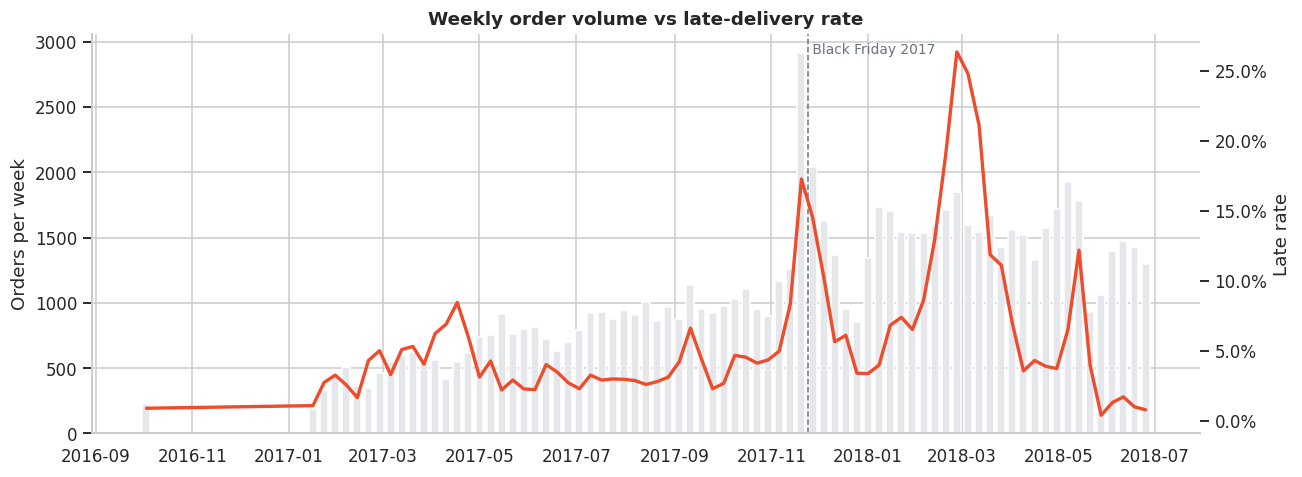

In [143]:
# Weekly trend (purchase cohort) — weeks with enough volume only
wk = (df.groupby('purchase_week')
        .agg(orders=('order_id', 'count'), late_rate=('is_late', 'mean'), avg_days=('total_days', 'mean'),
             handover=('handover_days', 'mean'), transit=('transit_days', 'mean'))
        .reset_index())
wk = wk[(wk.orders >= 100) & (wk.purchase_week < CENSOR_FROM)].copy()
wk['late_rate_pct'] = 100 * wk.late_rate

fig, ax = plt.subplots(figsize=(12, 4.5))
ax.bar(wk.purchase_week, wk.orders, width=5, color='#E5E7EB', label='Orders (left)')
ax.set_ylabel('Orders per week')
ax2 = ax.twinx()
ax2.plot(wk.purchase_week, wk.late_rate_pct, color=ACCENT, lw=2.2, label='Late rate % (right)')
ax2.yaxis.set_major_formatter(mtick.PercentFormatter())
ax2.set_ylabel('Late rate'); ax2.grid(False)
bf = pd.Timestamp('2017-11-24')
if wk.purchase_week.min() <= bf <= wk.purchase_week.max():
    ax.axvline(bf, color=GREY, ls='--', lw=1); ax.text(bf, ax.get_ylim()[1] * .95, ' Black Friday 2017', color=GREY, fontsize=9)
ax.set_title('Weekly order volume vs late-delivery rate')
save_fig('01_weekly_trend')

## 6. Root cause analysis
### 6.1 Where does the time go? Stage decomposition (on-time vs late)

,approval_days,handover_days,transit_days
is_late,,,
On-time,0.39,2.65,8.00
Late,0.50,5.57,27.88


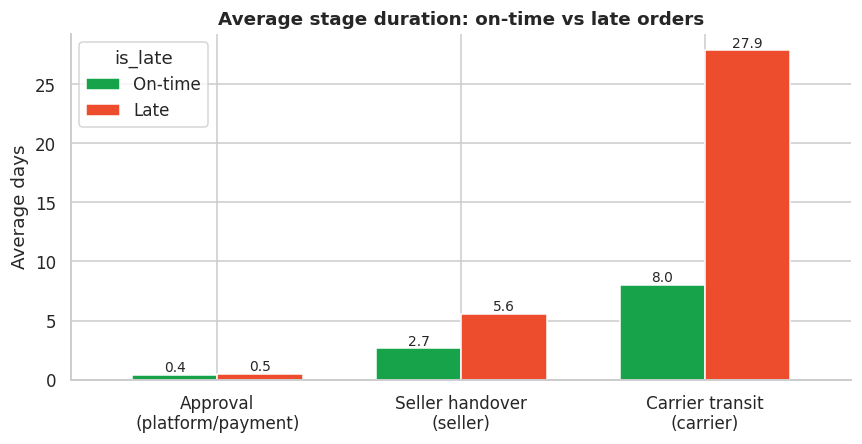

In [144]:
stage_cols = ['approval_days', 'handover_days', 'transit_days']
stage_lbl = {'approval_days': 'Approval\n(platform/payment)', 'handover_days': 'Seller handover\n(seller)', 'transit_days': 'Carrier transit\n(carrier)'}
cmp_ = df.groupby('is_late')[stage_cols].mean().rename(index={False: 'On-time', True: 'Late'})
display(cmp_)

ax = cmp_.rename(columns=stage_lbl).T.plot(kind='bar', figsize=(8, 4.2), color=[GREEN, ACCENT], width=.7)
ax.set_ylabel('Average days'); ax.set_title('Average stage duration: on-time vs late orders')
plt.xticks(rotation=0)
for c in ax.containers:
    ax.bar_label(c, fmt='%.1f', fontsize=9)
save_fig('02_stage_ontime_vs_late')

### 6.2 Distance-adjusted root-cause attribution
Untuk setiap order telat, kita hitung **excess days per tahap** dibanding benchmark order *on-time*:
- Approval & handover: benchmark = median tahap tersebut pada order on-time.
- **Transit: benchmark = waktu transit yang diharapkan berdasarkan jarak** (regresi linear transit ~ jarak, dilatih hanya pada order on-time). Ini yang membuat atribusi tidak menyalahkan kurir untuk rute yang memang jauh.
- Penyebab utama = tahap dengan excess terbesar. Jika **semua** excess < 1 hari, order diberi label **"Tight estimate"** (operasi normal, tetapi janji terlalu ketat).

> *Ini adalah heuristik atribusi, bukan pengukuran kausal. Jumlah excess tidak persis sama dengan delay days karena estimasi sudah memuat buffer.*

Benchmarks (on-time orders): approval 0.01d | handover 1.79d | transit = median on-time transit per distance bin (25 bins)


,late_orders,share_pct,owner,share_of_excess_days_pct
primary_driver,,,,
Carrier transit,5470,84.04,Carrier / logistics,81.53
Seller handover,999,15.35,Seller,16.48
Approval,25,0.38,Platform / payment,1.99
Tight estimate,15,0.23,Platform (ETA model),NaN


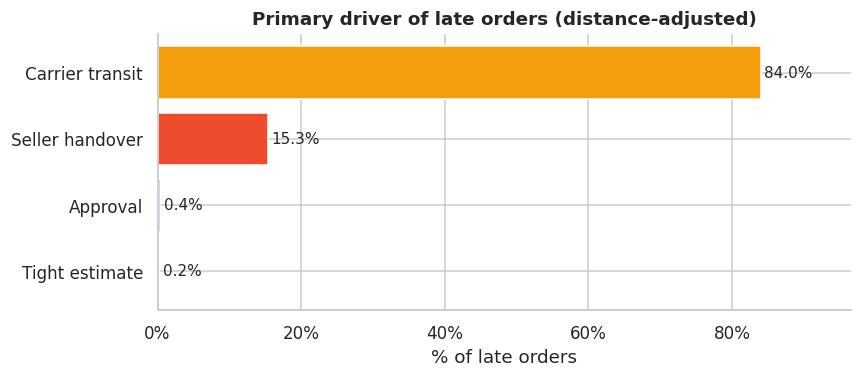

In [145]:
ontime = df[~df.is_late]
bench_appr, bench_hand = ontime.approval_days.median(), ontime.handover_days.median()
m = ontime.distance_km.notna()
bins = pd.qcut(ontime.loc[m, 'distance_km'], 25, duplicates='drop')
curve = (ontime.loc[m].groupby(bins, observed=True)
         .agg(km=('distance_km', 'median'), transit=('transit_days', 'median')).sort_values('km'))
curve['transit'] = np.maximum.accumulate(curve.transit.values)      # benchmark dipaksa monoton
def expected_transit_fn(km):
    return np.interp(km, curve.km.values, curve.transit.values)
print(f'Benchmarks (on-time orders): approval {bench_appr:.2f}d | handover {bench_hand:.2f}d | '
      f'transit = median on-time transit per distance bin ({len(curve)} bins)')

df['expected_transit'] = np.where(df.distance_km.notna(), expected_transit_fn(df.distance_km.fillna(0)),
                                  ontime.transit_days.median()).clip(1)
df['approval_excess'] = (df.approval_days - bench_appr).clip(lower=0)
df['handover_excess'] = (df.handover_days - bench_hand).clip(lower=0)
df['transit_excess'] = (df.transit_days - df.expected_transit).clip(lower=0)

EXC = ['approval_excess', 'handover_excess', 'transit_excess']
NAME = {'approval_excess': 'Approval', 'handover_excess': 'Seller handover', 'transit_excess': 'Carrier transit'}
TOL = 1.0
late = df[df.is_late]
driver = late[EXC].idxmax(axis=1).map(NAME)
df['primary_driver'] = (pd.Series(np.where(late[EXC].max(axis=1) < TOL, 'Tight estimate', driver), index=late.index)
                        .reindex(df.index))
OWNER = {'Approval': 'Platform / payment', 'Seller handover': 'Seller', 'Carrier transit': 'Carrier / logistics',
         'Tight estimate': 'Platform (ETA model)'}

drv = (df.primary_driver.value_counts().rename_axis('primary_driver').to_frame('late_orders')
         .assign(share_pct=lambda x: 100 * x.late_orders / x.late_orders.sum(),
                 owner=lambda x: x.index.map(OWNER)))
excess_share = (late[EXC].sum() / late[EXC].sum().sum() * 100).rename(index=NAME)
drv['share_of_excess_days_pct'] = excess_share.reindex(drv.index)
display(drv)

fig, ax = plt.subplots(figsize=(8, 3.6))
colors = {'Approval': BLUE, 'Seller handover': ACCENT, 'Carrier transit': '#F59E0B', 'Tight estimate': GREY}
ax.barh(drv.index[::-1], drv.share_pct[::-1], color=[colors[i] for i in drv.index[::-1]])
for i, v in enumerate(drv.share_pct[::-1]):
    ax.text(v + .5, i, f'{v:.1f}%', va='center', fontsize=10)
ax.set_xlabel('% of late orders'); ax.set_title('Primary driver of late orders (distance-adjusted)')
ax.xaxis.set_major_formatter(mtick.PercentFormatter()); ax.set_xlim(0, drv.share_pct.max() * 1.15)
save_fig('03_primary_driver')

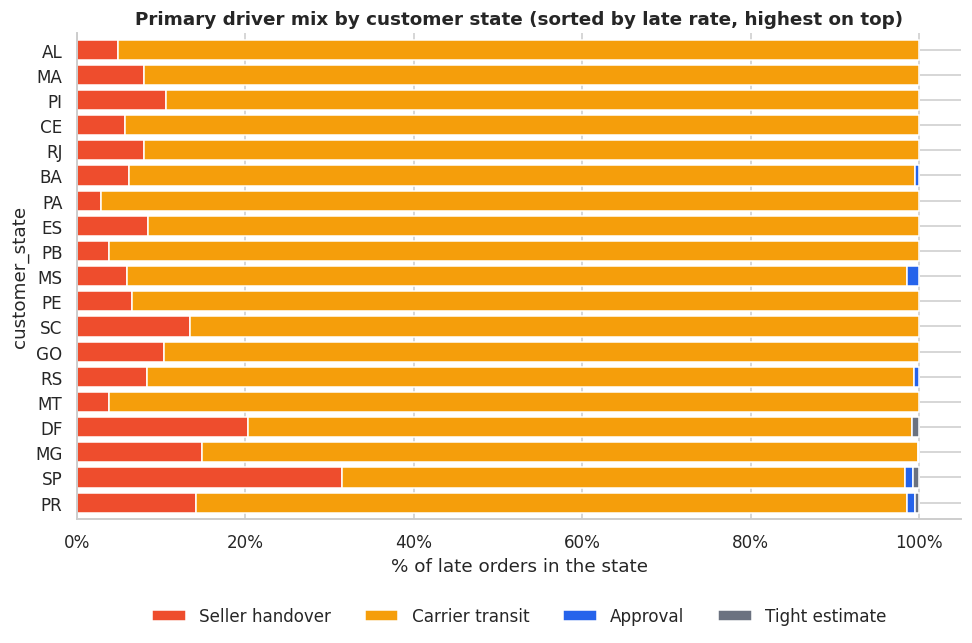

In [146]:
# Driver mix by customer state (states with enough late orders)
late = df[df.is_late]
st_n = late.customer_state.value_counts()
keep = st_n[st_n >= max(30, int(st_n.median() * .5))].index
mix = (pd.crosstab(late.customer_state[late.customer_state.isin(keep)],
                   late.primary_driver[late.customer_state.isin(keep)], normalize='index') * 100)
state_late = df.groupby('customer_state').is_late.mean() * 100
mix = mix.loc[state_late.reindex(mix.index).sort_values(ascending=False).index]
mix = mix[[c for c in ['Seller handover', 'Carrier transit', 'Approval', 'Tight estimate'] if c in mix.columns]]

ax = mix.plot(kind='barh', stacked=True, figsize=(9, max(4, .32 * len(mix))), color=[colors[c] for c in mix.columns], width=.8)
ax.invert_yaxis(); ax.set_xlabel('% of late orders in the state')
ax.set_title('Primary driver mix by customer state (sorted by late rate, highest on top)')
ax.xaxis.set_major_formatter(mtick.PercentFormatter()); ax.legend(loc='lower center', bbox_to_anchor=(.5, -.25), ncol=4, frameon=False)
save_fig('04_driver_mix_by_state')

### 6.3 Geography — region, state map, and distance-adjusted lanes

,orders,late_rate_pct,avg_days,transit_days,avg_distance_km
customer_region,,,,,
Northeast,8917,12.81,20.07,16.68,"1,780.81"
North,1776,8.56,22.65,19.29,"2,233.48"
Central-West,5529,6.60,15.10,11.90,900.19
Southeast,65266,6.18,10.81,7.57,359.18
South,13594,6.00,14.11,10.84,654.72


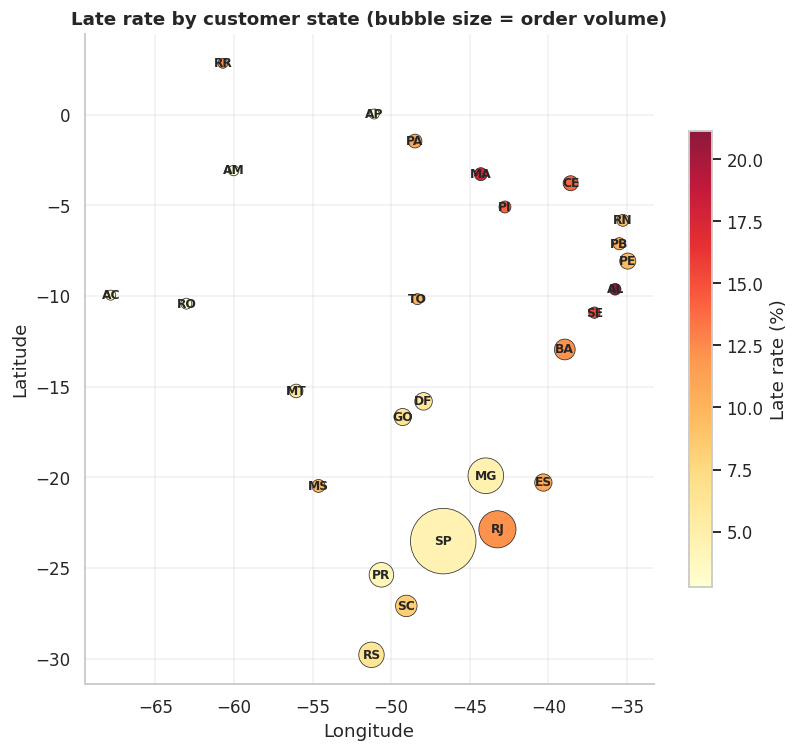

In [147]:
reg = (df.groupby('customer_region')
         .agg(orders=('order_id', 'count'), late_rate_pct=('is_late', lambda s: 100 * s.mean()),
              avg_days=('total_days', 'mean'), transit_days=('transit_days', 'mean'), avg_distance_km=('distance_km', 'mean'))
         .sort_values('late_rate_pct', ascending=False))
display(reg)

# Bubble "map" of states: x = lon, y = lat (centroid of zip prefixes), size = orders, colour = late rate
state_geo = (raw['geo'][raw['geo'].geolocation_lat.between(-34, 6) & raw['geo'].geolocation_lng.between(-74, -34)]
             .groupby('geolocation_state')[['geolocation_lat', 'geolocation_lng']].median())
stt = (df.groupby('customer_state')
         .agg(orders=('order_id', 'count'), late_rate_pct=('is_late', lambda s: 100 * s.mean()),
              avg_days=('total_days', 'mean'), median_buffer_days=('buffer_days', 'median'))
         .join(state_geo))
fig, ax = plt.subplots(figsize=(7.5, 7))
sc = ax.scatter(stt.geolocation_lng, stt.geolocation_lat, s=stt.orders / stt.orders.max() * 1800 + 40,
                c=stt.late_rate_pct, cmap='YlOrRd', edgecolor='k', linewidth=.5, alpha=.9)
for s, r in stt.dropna(subset=['geolocation_lat']).iterrows():
    ax.text(r.geolocation_lng, r.geolocation_lat, s, ha='center', va='center', fontsize=8, fontweight='bold')
plt.colorbar(sc, label='Late rate (%)', shrink=.7)
ax.set_xlabel('Longitude'); ax.set_ylabel('Latitude')
ax.set_title('Late rate by customer state (bubble size = order volume)'); ax.grid(alpha=.3)
save_fig('05_state_bubble_map')

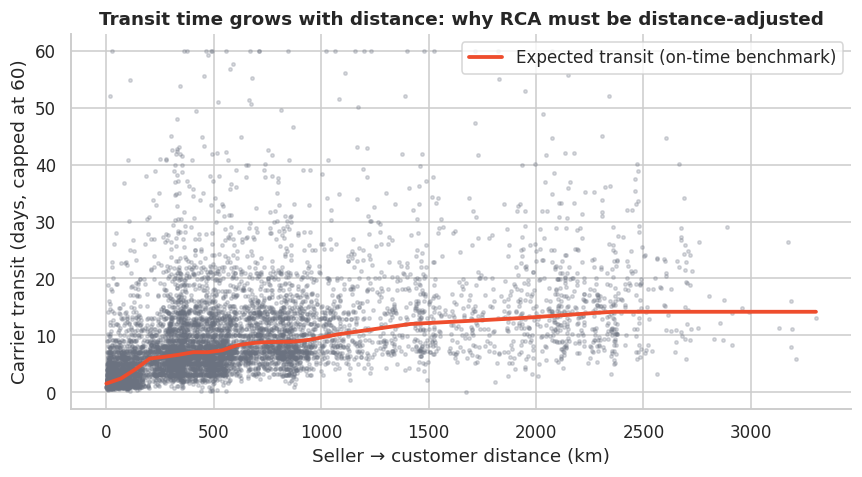

Lanes with the largest transit time beyond what distance explains (n ≥ 100 orders):


,orders,late_rate_pct,avg_distance_km,avg_transit_days,median_transit_excess_days
lane,,,,,
SP → AL,253,23.72,"1,901.72",21.68,6.03
SP → PA,672,12.05,"2,318.21",19.91,3.25
SP → MA,479,19.42,"2,175.11",18.64,2.89
SP → SC,2291,9.69,561.86,12.57,2.77
SP → BA,2279,12.86,"1,387.58",16.52,2.71
SP → GO,1396,7.45,747.32,12.81,2.56
MG → BA,359,9.75,"1,049.65",15.36,2.39
MG → SC,249,6.43,907.31,13.45,2.29
MG → GO,147,2.72,633.28,11.29,2.27


Best-performing lanes (faster than distance would predict):


,orders,late_rate_pct,avg_distance_km,avg_transit_days,median_transit_excess_days
lane,,,,,
RS → SP,652,1.23,860.47,6.91,-2.96
RS → MG,185,1.62,"1,294.22",8.61,-3.76
MA → SP,117,21.37,"2,332.86",10.96,-4.49
BA → SP,136,3.68,"1,418.08",8.34,-5.08
PE → SP,103,1.94,"2,098.18",9.67,-5.22


In [148]:
# Distance vs transit, and lane performance (seller_state → customer_state), distance-adjusted
samp = df.dropna(subset=['distance_km']).sample(min(8000, df.distance_km.notna().sum()), random_state=RANDOM_STATE)
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.scatter(samp.distance_km, samp.transit_days.clip(upper=60), s=5, alpha=.25, color=GREY)
xs = np.linspace(0, samp.distance_km.max(), 50)
ax.plot(xs, expected_transit_fn(xs), color=ACCENT, lw=2.5, label='Expected transit (on-time benchmark)')
ax.set_xlabel('Seller → customer distance (km)'); ax.set_ylabel('Carrier transit (days, capped at 60)')
ax.set_title('Transit time grows with distance: why RCA must be distance-adjusted'); ax.legend()
save_fig('06_distance_vs_transit')

lane = (df.dropna(subset=['seller_state', 'customer_state'])
          .assign(lane=lambda x: x.seller_state + ' → ' + x.customer_state,
                  transit_resid=lambda x: x.transit_days - x.expected_transit)
          .groupby('lane')
          .agg(orders=('order_id', 'count'), late_rate_pct=('is_late', lambda s: 100 * s.mean()),
               avg_distance_km=('distance_km', 'mean'), avg_transit_days=('transit_days', 'mean'),
               median_transit_excess_days=('transit_resid', 'median'))
          .query('orders >= 100').sort_values('median_transit_excess_days', ascending=False))
lane.to_csv(os.path.join(OUT_DIR, 'lane_performance.csv'))
print('Lanes with the largest transit time beyond what distance explains (n ≥ 100 orders):')
display(lane.head(10))
print('Best-performing lanes (faster than distance would predict):')
display(lane.tail(5))

In [149]:
_chk = df[~df.is_late].assign(dbin=lambda x: pd.qcut(x.distance_km, 8, duplicates='drop'),
                              resid=lambda x: x.transit_days - x.expected_transit)
display(_chk.groupby('dbin', observed=True).agg(orders=('order_id', 'count'), median_resid_days=('resid', 'median')))

,orders,median_resid_days
dbin,,
"(-0.001, 49.631]",11019,0.02
"(49.631, 173.25]",11018,-0.05
"(173.25, 331.387]",11018,0.02
"(331.387, 426.233]",11018,-0.02
"(426.233, 549.31]",11018,-0.07
"(549.31, 784.25]",11018,0.12
"(784.25, 1168.016]",11018,-0.17
"(1168.016, 3399.191]",11019,0.10


### 6.4 Estimate calibration — is the promise realistic?
`buffer_days` = tanggal estimasi − tanggal diterima. Positif = datang lebih awal dari janji, negatif = telat. Estimasi yang sehat punya buffer positif yang **tidak terlalu besar** (terlalu longgar = janji tidak kompetitif) dan late rate rendah.

,orders,promised_days,actual_days,median_buffer_days,late_rate_pct,early_10d_pct
customer_state,,,,,,
AL,393,31.46,22.33,10.00,21.12,51.65
MA,704,30.21,19.24,10.00,17.76,53.41
SE,333,29.55,18.05,13.00,15.32,61.56
PI,469,29.51,16.38,14.00,14.07,63.33
CE,1259,31.29,18.23,13.00,13.98,62.11
RJ,12210,24.59,12.09,13.00,12.22,63.91
BA,3210,29.01,16.95,12.00,12.18,62.24
PA,936,36.12,21.09,16.00,11.11,72.33
ES,1968,25.03,13.71,12.00,10.82,61.23


Overall: median buffer = 12 days early | 63.9% of orders arrive ≥10 days before the promise | 6.8% arrive after it


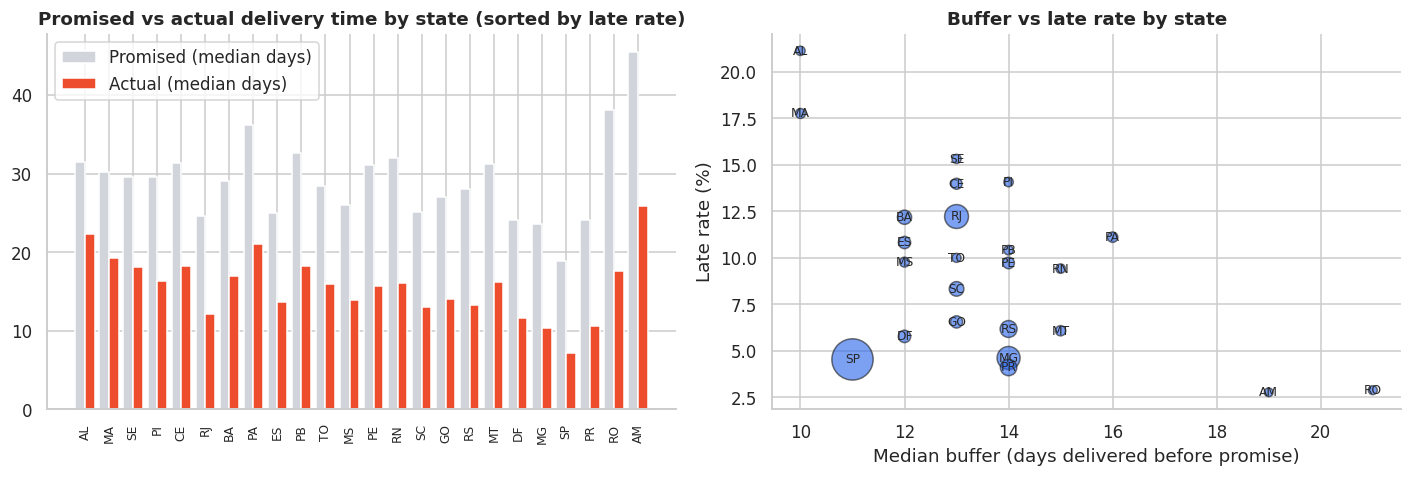

Median buffer by purchase month (shifts reveal changes in ETA policy or in operations):


purchase_month,2016-10,2017-01,2017-02,2017-03,2017-04,2017-05,2017-06,2017-07,2017-08,2017-09,2017-10,2017-11,2017-12,2018-01,2018-02,2018-03,2018-04,2018-05,2018-06,2018-07,2018-08
n,261.00,747.00,"1,638.00","2,545.00","2,279.00","3,530.00","3,130.00","3,841.00","4,190.00","4,136.00","4,478.00","7,287.00","5,508.00","7,045.00","6,543.00","7,001.00","6,409.00","6,681.00","5,973.00","5,593.00","6,265.00"
buffer,39.00,29.00,20.00,14.00,14.00,14.00,13.00,13.00,13.00,12.00,12.00,10.00,14.00,14.00,10.00,8.00,13.00,12.00,19.00,11.00,7.00
late_pct,0.77,2.95,2.99,4.56,6.58,3.00,3.00,2.81,2.91,4.35,4.18,12.41,7.43,5.71,14.15,18.97,4.70,6.57,1.17,3.61,6.24


In [150]:
cal = (df.groupby('customer_state')
         .agg(orders=('order_id', 'count'), promised_days=('estimated_days', 'median'), actual_days=('total_days', 'median'),
              median_buffer_days=('buffer_days', 'median'), late_rate_pct=('is_late', lambda s: 100 * s.mean()),
              early_10d_pct=('buffer_days', lambda s: 100 * (s >= 10).mean()))
         .query('orders >= 100').sort_values('late_rate_pct', ascending=False))
display(cal.head(10))

overall_buffer = df.buffer_days.median()
print(f'Overall: median buffer = {overall_buffer:.0f} days early | {100 * (df.buffer_days >= 10).mean():.1f}% of orders arrive ≥10 days before the promise '
      f'| {100 * df.is_late.mean():.1f}% arrive after it')

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
x = np.arange(len(cal)); w = .4
axes[0].bar(x - w / 2, cal.promised_days, w, label='Promised (median days)', color='#D1D5DB')
axes[0].bar(x + w / 2, cal.actual_days, w, label='Actual (median days)', color=ACCENT)
axes[0].set_xticks(x); axes[0].set_xticklabels(cal.index, rotation=90, fontsize=8)
axes[0].set_title('Promised vs actual delivery time by state (sorted by late rate)'); axes[0].legend()
axes[1].scatter(cal.median_buffer_days, cal.late_rate_pct, s=cal.orders / cal.orders.max() * 700 + 30, color=BLUE, alpha=.6, edgecolor='k')
for s, r in cal.iterrows():
    axes[1].text(r.median_buffer_days, r.late_rate_pct, s, fontsize=8, ha='center', va='center')
axes[1].set_xlabel('Median buffer (days delivered before promise)'); axes[1].set_ylabel('Late rate (%)')
axes[1].set_title('Buffer vs late rate by state')
save_fig('07_estimate_calibration')

mb = df.groupby('purchase_month').agg(n=('order_id', 'count'), buffer=('buffer_days', 'median'), late=('is_late', 'mean')).query('n >= 100')
print('Median buffer by purchase month (shifts reveal changes in ETA policy or in operations):')
display(mb.assign(late_pct=100 * mb.late).drop(columns='late').T)

### 6.5 Seller concentration (Pareto) & scorecard
Berapa persen seller yang menyebabkan sebagian besar keterlambatan yang *berasal dari sisi seller* (primary driver = Seller handover)? Order multi-seller dikaitkan ke seller item pertama (lihat Limitations).

2,951 sellers | 67 sellers (2.3%) cause 50% and 220 sellers (7.5%) cause 80% of seller-driven late orders


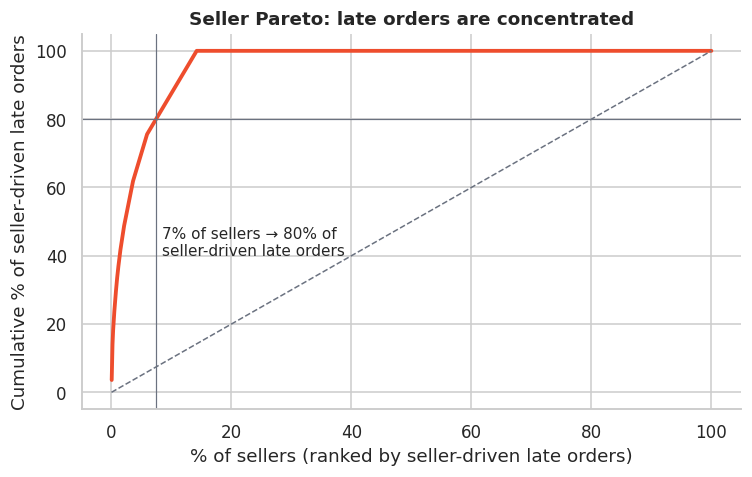

Seller tiers (≥30 orders):


,sellers
tier,
Healthy,389
Critical,123
Watch,99


,orders,late_rate_pct,avg_handover_days,p90_handover_days,avg_review,seller_state,seller_driven_late_orders,tier
seller_id,,,,,,,,
06a2c3af7b3aee5d69171b0e14f0ee87,369,20.05,4.68,11.63,3.99,MA,36.00,Critical
1025f0e2d44d7041d6cf58b6550e0bfa,886,8.01,3.85,7.40,4.02,SP,29.00,Critical
7c67e1448b00f6e969d365cea6b010ab,966,9.21,11.43,17.08,3.50,SP,27.00,Critical
88460e8ebdecbfecb5f9601833981930,235,17.87,7.74,16.91,3.43,PR,26.00,Critical
54965bbe3e4f07ae045b90b0b8541f52,70,31.43,15.52,40.77,3.12,PR,22.00,Critical
2eb70248d66e0e3ef83659f71b244378,185,11.35,10.88,20.68,2.78,SP,16.00,Critical
a49928bcdf77c55c6d6e05e09a9b4ca5,94,22.34,6.99,12.70,3.06,SP,13.00,Critical
beadbee30901a7f61d031b6b686095ad,63,23.81,7.21,22.00,3.94,SP,12.00,Critical
855668e0971d4dfd7bef1b6a4133b41b,296,12.84,5.89,14.35,3.86,SP,10.00,Critical


In [151]:
seller_late = (df[df.primary_driver == 'Seller handover'].groupby('seller_id').size()
               .rename('seller_driven_late_orders').sort_values(ascending=False).to_frame())
seller_all = (df.groupby('seller_id')
                .agg(orders=('order_id', 'count'), late_rate_pct=('is_late', lambda s: 100 * s.mean()),
                     avg_handover_days=('handover_days', 'mean'), p90_handover_days=('handover_days', lambda s: s.quantile(.9)),
                     avg_review=('review_score', 'mean'), seller_state=('seller_state', 'first')))
sc_ = seller_all.join(seller_late).fillna({'seller_driven_late_orders': 0})

# Pareto curve over all sellers that have at least one order
s_sorted = sc_.sort_values('seller_driven_late_orders', ascending=False)
cum = s_sorted.seller_driven_late_orders.cumsum() / s_sorted.seller_driven_late_orders.sum()
x_pct = np.arange(1, len(s_sorted) + 1) / len(s_sorted)
n50, n80 = int((cum < .5).sum() + 1), int((cum < .8).sum() + 1)
pct50, pct80 = 100 * n50 / len(s_sorted), 100 * n80 / len(s_sorted)
print(f'{len(s_sorted):,} sellers | {n50} sellers ({pct50:.1f}%) cause 50% and {n80} sellers ({pct80:.1f}%) cause 80% of seller-driven late orders')

fig, ax = plt.subplots(figsize=(7, 4.5))
ax.plot(100 * x_pct, 100 * cum.values, color=ACCENT, lw=2.5); ax.plot([0, 100], [0, 100], color=GREY, ls='--', lw=1)
ax.axhline(80, color=GREY, lw=.8); ax.axvline(pct80, color=GREY, lw=.8)
ax.text(pct80 + 1, 40, f'{pct80:.0f}% of sellers → 80% of\nseller-driven late orders', fontsize=10)
ax.set_xlabel('% of sellers (ranked by seller-driven late orders)'); ax.set_ylabel('Cumulative % of seller-driven late orders')
ax.set_title('Seller Pareto: late orders are concentrated')
save_fig('08_seller_pareto')

# Scorecard: sellers with enough volume, tiered relative to the platform average
overall_late = 100 * df.is_late.mean()
card = sc_[sc_.orders >= 30].copy()
impact_cut = card.seller_driven_late_orders.quantile(.9)
card['tier'] = np.select([(card.late_rate_pct >= 2 * overall_late) | (card.seller_driven_late_orders >= impact_cut),
                          card.late_rate_pct >= 1.2 * overall_late],
                         ['Critical', 'Watch'], default='Healthy')
card = card.sort_values('seller_driven_late_orders', ascending=False)
print('Seller tiers (≥30 orders):'); display(card.tier.value_counts().to_frame('sellers'))
display(card.head(10))
card.reset_index().to_csv(os.path.join(OUT_DIR, 'seller_scorecard.csv'), index=False)

### 6.6 Category view

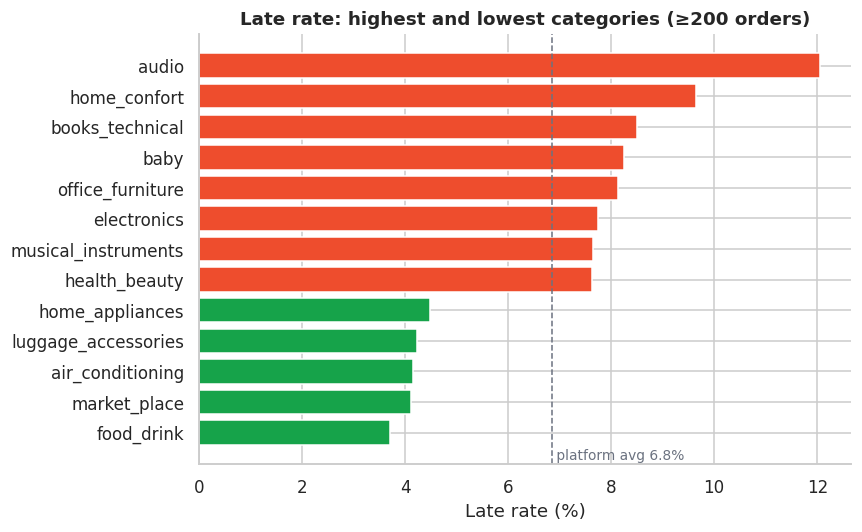

,orders,late_rate_pct,avg_days,avg_handover,avg_weight_g,avg_distance_km
category,,,,,,
audio,340,12.06,13.57,2.59,"1,254.83",570.94
home_confort,363,9.64,13.63,2.38,"3,111.98",534.33
books_technical,247,8.50,10.76,2.53,"1,019.88",547.83
baby,2725,8.26,12.80,3.01,"3,369.69",609.36
office_furniture,1241,8.14,20.75,9.96,"11,346.10",566.68
electronics,2479,7.75,12.99,2.35,774.33,626.89
musical_instruments,601,7.65,13.18,2.90,"3,184.73",649.40
health_beauty,8458,7.64,12.16,2.69,"1,073.39",678.40


In [152]:
cat = (df.groupby('category')
         .agg(orders=('order_id', 'count'), late_rate_pct=('is_late', lambda s: 100 * s.mean()),
              avg_days=('total_days', 'mean'), avg_handover=('handover_days', 'mean'),
              avg_weight_g=('product_weight_g', 'mean'), avg_distance_km=('distance_km', 'mean'))
         .query('orders >= 200').sort_values('late_rate_pct', ascending=False))
top = pd.concat([cat.head(8), cat.tail(5)])
fig, ax = plt.subplots(figsize=(8, 5))
ax.barh(top.index[::-1], top.late_rate_pct[::-1], color=[ACCENT if v >= overall_late else GREEN for v in top.late_rate_pct[::-1]])
ax.axvline(overall_late, color=GREY, ls='--', lw=1); ax.text(overall_late, -.9, f' platform avg {overall_late:.1f}%', color=GREY, fontsize=9)
ax.set_xlabel('Late rate (%)'); ax.set_title('Late rate: highest and lowest categories (≥200 orders)')
save_fig('09_category_late_rate')
display(cat.head(8))

## 7. Does lateness hurt reviews? (association, controlled)
Perbandingan mentah bisa menyesatkan: order telat cenderung berjarak jauh, dari wilayah tertentu, atau kategori tertentu, dan faktor-faktor itu sendiri bisa mempengaruhi review. Karena itu kita pakai regresi dengan kontrol kategori, state, jarak, harga, ongkir, dan jumlah item/seller.

> ⚠️ Hasil dibaca sebagai **asosiasi setelah kontrol**, bukan efek kausal. Masih ada confounder yang tidak teramati (kualitas produk, ekspektasi customer).

In [153]:
import statsmodels.formula.api as smf

rd = df.dropna(subset=['review_score', 'distance_km']).copy()
top_cats = rd.category.value_counts().head(25).index
rd['cat_grp'] = np.where(rd.category.isin(top_cats), rd.category, 'other')
rd['late_int'] = rd.is_late.astype(int)
rd['low_review'] = (rd.review_score <= 2).astype(int)
rd['dist_k'], rd['price_100'], rd['freight_10'] = rd.distance_km / 1000, rd.price_total / 100, rd.freight_total / 10
rd['delay_bucket'] = rd.delay_bucket.astype(str)
ctrl = 'dist_k + price_100 + freight_10 + n_items + n_sellers + C(cat_grp) + C(customer_state)'

# Raw (uncontrolled) view
raw_view = rd.groupby('delay_bucket').agg(orders=('order_id', 'count'), avg_review=('review_score', 'mean'),
                                         pct_1_star=('review_score', lambda s: 100 * (s == 1).mean()),
                                         pct_low_1_2=('low_review', lambda s: 100 * s.mean()))
order_ = ['On-time', '1-3 days late', '4-7 days late', '8-14 days late', '>14 days late']
raw_view = raw_view.reindex(order_)
display(raw_view)

m_bin = smf.ols(f'review_score ~ late_int + {ctrl}', data=rd).fit(cov_type='HC1')
m_low = smf.ols(f'low_review ~ late_int + {ctrl}', data=rd).fit(cov_type='HC1')
raw_gap = rd.groupby('late_int').review_score.mean().diff().iloc[-1]
ci = m_bin.conf_int().loc['late_int']; ci_l = m_low.conf_int().loc['late_int']
print(f'Raw gap in avg review (late − on-time): {raw_gap:+.2f} stars')
print(f'Controlled effect on review score     : {m_bin.params["late_int"]:+.2f} stars  (95% CI {ci[0]:+.2f} to {ci[1]:+.2f})')
print(f'Controlled effect on P(review ≤ 2)    : {100 * m_low.params["late_int"]:+.1f} pp   (95% CI {100 * ci_l[0]:+.1f} to {100 * ci_l[1]:+.1f})')

,orders,avg_review,pct_1_star,pct_low_1_2
delay_bucket,,,,
On-time,87661,4.29,6.63,9.27
1-3 days late,1831,3.29,25.12,32.22
4-7 days late,1725,2.10,58.49,67.65
8-14 days late,1438,1.67,70.58,80.18
>14 days late,1317,1.71,69.25,78.74


Raw gap in avg review (late − on-time): -2.02 stars
Controlled effect on review score     : -2.01 stars  (95% CI -2.05 to -1.97)
Controlled effect on P(review ≤ 2)    : +53.1 pp   (95% CI +51.9 to +54.3)


Reviews created BEFORE delivery: all 5.2% | late orders 74.5% | on-time orders 0.3%
Sensitivity (reviews written after delivery, n=89,052): controlled effect = -0.77 stars (95% CI -0.84 to -0.70)


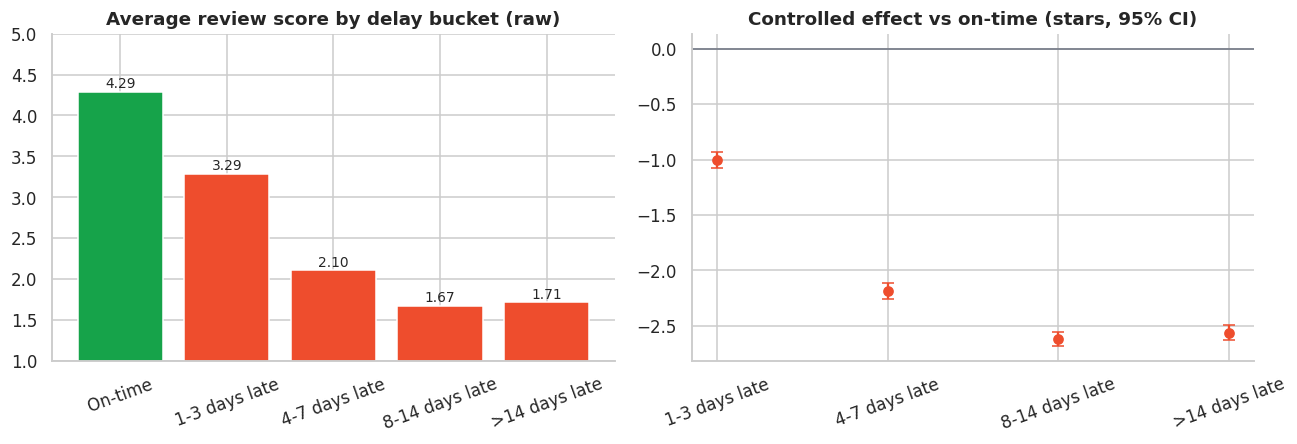

In [154]:
# Dose-response: effect by lateness bucket (reference = on-time), controlled
m_dose = smf.ols(f'review_score ~ C(delay_bucket, Treatment("On-time")) + {ctrl}', data=rd).fit(cov_type='HC1')
dose = m_dose.params.filter(like='delay_bucket').to_frame('coef')
dose['lo'], dose['hi'] = m_dose.conf_int().loc[dose.index, 0], m_dose.conf_int().loc[dose.index, 1]
dose.index = dose.index.str.extract(r'\[T\.(.*)\]')[0]
dose = dose.reindex([b for b in order_ if b != 'On-time'])

pre = rd.review_creation_date.dt.normalize() < rd.order_delivered_customer_date.dt.normalize()
print(f'Reviews created BEFORE delivery: all {pre.mean():.1%} | late orders {pre[rd.is_late].mean():.1%} | on-time orders {pre[~rd.is_late].mean():.1%}')

# Sensitivity: only reviews created on/after the delivery date (survey could be sent before delivery)
rd_after = rd[rd.review_creation_date.dt.normalize() >= rd.order_delivered_customer_date.dt.normalize()]
m_after = smf.ols(f'review_score ~ late_int + {ctrl}', data=rd_after).fit(cov_type='HC1')
ci_a = m_after.conf_int().loc['late_int']
print(f'Sensitivity (reviews written after delivery, n={len(rd_after):,}): controlled effect = {m_after.params["late_int"]:+.2f} stars (95% CI {ci_a[0]:+.2f} to {ci_a[1]:+.2f})')

fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
axes[0].bar(raw_view.index, raw_view.avg_review, color=[GREEN] + [ACCENT] * 4)
axes[0].set_ylim(1, 5); axes[0].set_title('Average review score by delay bucket (raw)'); axes[0].tick_params(axis='x', rotation=20)
for i, v in enumerate(raw_view.avg_review):
    axes[0].text(i, v + .05, f'{v:.2f}', ha='center', fontsize=9)
axes[1].errorbar(dose.index, dose.coef, yerr=[dose.coef - dose.lo, dose.hi - dose.coef], fmt='o', color=ACCENT, capsize=4)
axes[1].axhline(0, color=GREY, lw=1); axes[1].set_title('Controlled effect vs on-time (stars, 95% CI)'); axes[1].tick_params(axis='x', rotation=20)
save_fig('10_review_impact')

## 8. Peak-season analysis — does the bottleneck shift under load?

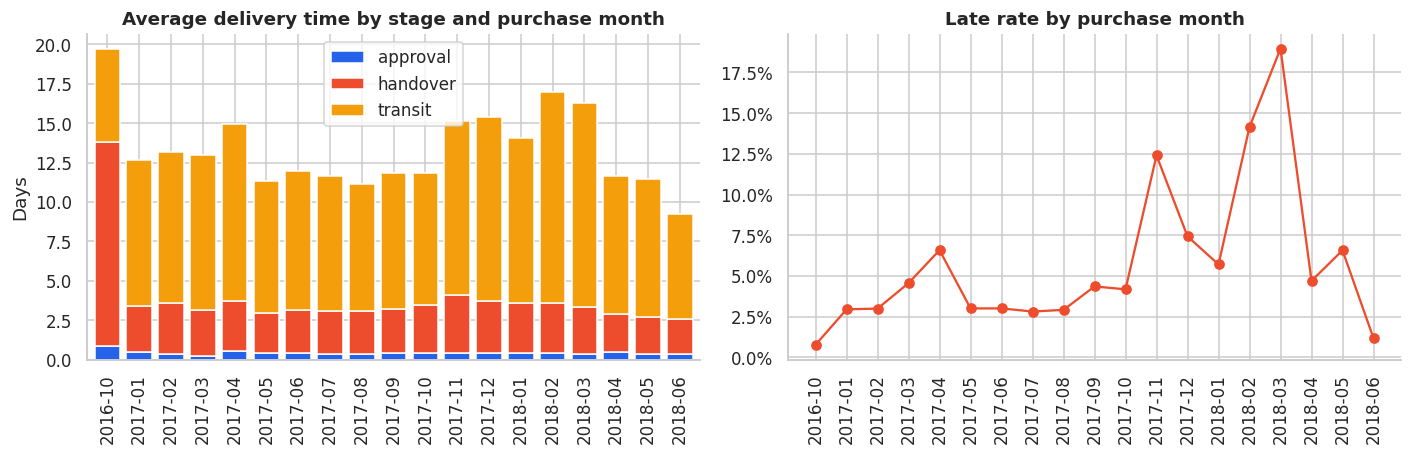

Share of late orders by primary driver, per purchase month (%):


primary_driver,Approval,Carrier transit,Seller handover,Tight estimate
purchase_month,,,,
2016-10,0.00,0.00,100.00,0.00
2017-01,0.00,77.30,22.70,0.00
2017-02,0.00,57.10,42.90,0.00
2017-03,0.90,84.50,14.70,0.00
2017-04,0.00,80.70,19.30,0.00
2017-05,0.00,80.20,19.80,0.00
2017-06,0.00,74.50,25.50,0.00
2017-07,0.00,89.80,10.20,0.00
2017-08,0.80,77.90,21.30,0.00


In [155]:
mo = (df.groupby('purchase_month')
        .agg(orders=('order_id', 'count'), late_pct=('is_late', lambda s: 100 * s.mean()),
             approval=('approval_days', 'mean'), handover=('handover_days', 'mean'), transit=('transit_days', 'mean'))
        .query('orders >= 100'))
mo = mo[mo.index < CENSOR_FROM.strftime('%Y-%m')]

fig, axes = plt.subplots(1, 2, figsize=(13, 4.3))
mo[['approval', 'handover', 'transit']].plot(kind='bar', stacked=True, ax=axes[0], color=[BLUE, ACCENT, '#F59E0B'], width=.8)
axes[0].set_title('Average delivery time by stage and purchase month'); axes[0].set_ylabel('Days'); axes[0].set_xlabel('')
axes[1].plot(mo.index, mo.late_pct, marker='o', color=ACCENT); axes[1].set_title('Late rate by purchase month')
axes[1].yaxis.set_major_formatter(mtick.PercentFormatter()); axes[1].tick_params(axis='x', rotation=90)
save_fig('11_stage_by_month')

late_drv_m = (pd.crosstab(df.loc[df.is_late, 'purchase_month'], df.loc[df.is_late, 'primary_driver'], normalize='index') * 100)
late_drv_m = late_drv_m.loc[late_drv_m.index.isin(mo.index)]
print('Share of late orders by primary driver, per purchase month (%):')
display(late_drv_m.round(1))

## 9. Late-risk model — predict at checkout, explain with SHAP
Tujuan bisnis: menandai order berisiko telat **saat checkout** agar bisa diberi ETA yang lebih realistis, seller diprioritaskan, atau customer diberi notifikasi proaktif.
- **Hanya fitur yang diketahui saat checkout** (tanpa durasi approval/handover/transit, karena itu leakage).
- **Time-based split**: train < 2018-04-01 (validasi = 15% terakhir train) dan test ≥ 2018-04-01. Ini jauh lebih jujur daripada random split karena pola operasional berubah antar waktu.

In [156]:
try:
    import lightgbm as lgb
    from sklearn.metrics import roc_auc_score, average_precision_score
except ImportError as e:
    raise ImportError('Run `!pip install lightgbm` in a cell first (needs Internet ON in Kaggle).') from e
CUT = pd.Timestamp('2018-04-01')
ml = df.copy()
ml['freight_ratio'] = ml.freight_total / (ml.price_total + 1)

pday = ml.purchase_ts.dt.normalize()
ml['lane'] = ml.seller_state.astype(str) + '>' + ml.customer_state.astype(str)
# (a) beban platform: jumlah order 7 hari sebelumnya
cnt = pd.to_datetime(raw['orders'].order_purchase_timestamp).dt.normalize().value_counts().sort_index()
cnt = cnt.reindex(pd.date_range(cnt.index.min(), cnt.index.max()), fill_value=0)
ml['volume_7d'] = pday.map(cnt.rolling(7).sum().shift(1))
# (b)(c) late rate 14 hari terakhir, dikunci ke tanggal DELIVERY dan digeser 1 hari (hanya masa lalu)
dday = ml.order_delivered_customer_date.dt.normalize()
full = pd.date_range(dday.min(), pday.max())
g = ml.assign(dday=dday).groupby(['lane', 'dday']).agg(n=('is_late', 'size'), late=('is_late', 'sum')).reset_index()
pv_n = g.pivot(index='dday', columns='lane', values='n').reindex(full).fillna(0)
pv_l = g.pivot(index='dday', columns='lane', values='late').reindex(full).fillna(0)
r_n, r_l = pv_n.rolling(14, min_periods=1).sum().shift(1), pv_l.rolling(14, min_periods=1).sum().shift(1)
plat = (r_l.sum(axis=1) / r_n.sum(axis=1)).rename('plat')
lane_pos, day_pos = pv_n.columns.get_indexer(ml.lane), full.get_indexer(pday)
ok = (lane_pos >= 0) & (day_pos >= 0)
n_arr, l_arr = np.full(len(ml), np.nan), np.full(len(ml), np.nan)
n_arr[ok], l_arr[ok] = r_n.values[day_pos[ok], lane_pos[ok]], r_l.values[day_pos[ok], lane_pos[ok]]
ml['platform_late_14d'] = pday.map(plat)
k = 5   # lane kecil ditarik ke rata-rata platform
ml['lane_late_14d'] = (l_arr + k * ml.platform_late_14d) / (n_arr + k)

CAT = ['seller_state', 'customer_state', 'category']
NUM = ['distance_km', 'same_state', 'same_region', 'price_total', 'freight_total', 'freight_ratio', 'product_weight_g',
       'volume_cm3', 'n_items', 'n_sellers', 'purchase_dow', 'purchase_hour', 'estimated_days']


for c in CAT:
    ml[c] = ml[c].astype(pd.CategoricalDtype(sorted(ml[c].dropna().unique())))
X, y = ml[NUM + CAT], ml.is_late.astype(int)

train_all = ml.purchase_ts < CUT
tr_idx = ml[train_all].sort_values('purchase_ts').index
val_cut = int(len(tr_idx) * .85)
idx_tr, idx_va, idx_te = tr_idx[:val_cut], tr_idx[val_cut:], ml[(~train_all) & (~ml.maybe_censored)].index

print(f'train {len(idx_tr):,} | val {len(idx_va):,} | test {len(idx_te):,} | late rate train {y[idx_tr].mean():.1%} → test {y[idx_te].mean():.1%}')

model = lgb.LGBMClassifier(n_estimators=600, learning_rate=0.04, num_leaves=31, min_child_samples=40,
                           subsample=.8, subsample_freq=1, colsample_bytree=.8, reg_lambda=2.0,
                           random_state=RANDOM_STATE, verbose=-1)
model.fit(X.loc[idx_tr], y[idx_tr], eval_set=[(X.loc[idx_va], y[idx_va])], eval_metric='auc',
          callbacks=[lgb.early_stopping(50, verbose=False), lgb.log_evaluation(0)])
p_te = model.predict_proba(X.loc[idx_te])[:, 1]
auc, ap, base = roc_auc_score(y[idx_te], p_te), average_precision_score(y[idx_te], p_te), y[idx_te].mean()
print(f'Out-of-time test → ROC-AUC {auc:.3f} | PR-AUC {ap:.3f} (random baseline {base:.3f}) | best iteration {model.best_iteration_}')

train 54,536 | val 9,625 | test 19,063 | late rate train 5.9% → test 4.2%
Out-of-time test → ROC-AUC 0.722 | PR-AUC 0.120 (random baseline 0.042) | best iteration 126


,flag_top_pct_orders,late_orders_caught_pct,precision_pct,lift_vs_random
0,5,20.25,17.21,4.05
1,10,32.84,13.96,3.28
2,20,48.02,10.20,2.40
3,30,58.77,8.32,1.96


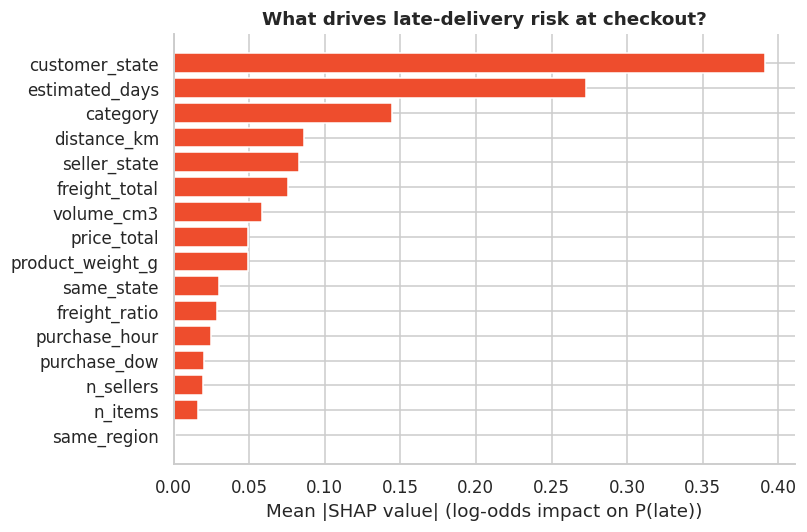

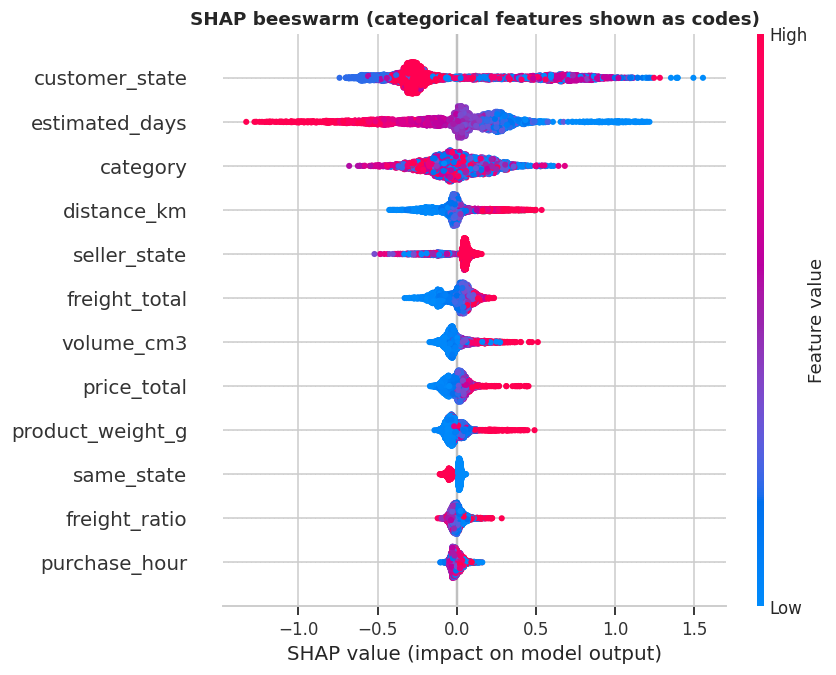

In [157]:
# Business lift: how many late orders do we catch by reviewing only the riskiest X% of orders?
te = pd.DataFrame({'p': p_te, 'late': y[idx_te].values}).sort_values('p', ascending=False).reset_index(drop=True)
rows = []
for frac in (.05, .10, .20, .30):
    k = int(len(te) * frac); cap = te.late[:k].sum() / te.late.sum(); prec = te.late[:k].mean()
    rows.append({'flag_top_pct_orders': int(frac * 100), 'late_orders_caught_pct': 100 * cap,
                 'precision_pct': 100 * prec, 'lift_vs_random': prec / base})
lift = pd.DataFrame(rows); display(lift)

# Explainability: native TreeSHAP values from LightGBM (identical to SHAP's TreeExplainer)
Xs = X.loc[idx_te].sample(min(4000, len(idx_te)), random_state=RANDOM_STATE)
sv = model.booster_.predict(Xs, pred_contrib=True)[:, :-1]
imp = pd.Series(np.abs(sv).mean(0), index=Xs.columns).sort_values()
fig, ax = plt.subplots(figsize=(7.5, 5))
ax.barh(imp.index, imp.values, color=ACCENT); ax.set_xlabel('Mean |SHAP value| (log-odds impact on P(late))')
ax.set_title('What drives late-delivery risk at checkout?')
save_fig('12_shap_importance')

try:
    import shap
    Xp = Xs.copy()
    for c in CAT:
        Xp[c] = Xp[c].cat.codes
    shap.summary_plot(sv, Xp, show=False, max_display=12)
    plt.title('SHAP beeswarm (categorical features shown as codes)'); save_fig('13_shap_beeswarm')
except Exception as e:
    print('Optional SHAP beeswarm skipped:', type(e).__name__)

## 10. Export for the dashboard (Power BI / Looker Studio)
Tabel teragregasi supaya ringan untuk Looker Studio (upload ke Google Sheets/BigQuery) dan siap dipakai di Power BI.

In [158]:
export_cols = ['order_id', 'purchase_ts', 'purchase_week', 'purchase_month', 'customer_state', 'customer_region', 'seller_state',
               'seller_id', 'category', 'distance_km', 'approval_days', 'handover_days', 'transit_days', 'total_days', 'estimated_days',
               'is_late', 'delay_days', 'delay_bucket', 'buffer_days', 'primary_driver', 'review_score', 'price_total', 'freight_total']
fact = df[export_cols].copy(); fact['is_late'] = fact.is_late.astype(int)
fact['driver_owner'] = fact.primary_driver.map(OWNER)
fact.to_csv(os.path.join(OUT_DIR, 'fact_orders.csv'), index=False)

wk_out = (df.groupby('purchase_week').agg(orders=('order_id', 'count'), late_orders=('is_late', 'sum'), avg_delivery_days=('total_days', 'mean'),
                                         avg_approval=('approval_days', 'mean'), avg_handover=('handover_days', 'mean'), avg_transit=('transit_days', 'mean'),
                                         avg_review=('review_score', 'mean')).reset_index())
wk_out['late_rate_pct'] = 100 * wk_out.late_orders / wk_out.orders
wk_out.query('orders >= 100').to_csv(os.path.join(OUT_DIR, 'kpi_weekly.csv'), index=False)
stt.reset_index().rename(columns={'index': 'customer_state'}).to_csv(os.path.join(OUT_DIR, 'kpi_state.csv'), index=False)
cat.reset_index().to_csv(os.path.join(OUT_DIR, 'kpi_category.csv'), index=False)
drv.reset_index().to_csv(os.path.join(OUT_DIR, 'rca_primary_driver.csv'), index=False)
raw_view.reset_index().to_csv(os.path.join(OUT_DIR, 'review_by_delay_bucket.csv'), index=False)
print(pd.DataFrame({'file': sorted(os.listdir(OUT_DIR)),
                    'KB': [round(os.path.getsize(os.path.join(OUT_DIR, f)) / 1024) for f in sorted(os.listdir(OUT_DIR))]}))

                         file     KB
0             fact_orders.csv  25995
1            kpi_category.csv      5
2               kpi_state.csv      2
3              kpi_weekly.csv     11
4        lane_performance.csv      6
5       management_summary.md      2
6      rca_primary_driver.csv      0
7  review_by_delay_bucket.csv      0
8        seller_scorecard.csv     72


## 11. One-page management summary (auto-generated from the numbers above)

In [159]:
top_driver = drv.index[0]
st_rank = stt[stt.orders >= 300].sort_values('late_rate_pct', ascending=False)
worst_states = ', '.join(f'{s} ({r.late_rate_pct:.1f}%)' for s, r in st_rank.head(3).iterrows())
worst_lane = lane.head(1)
seller_driven_total = df.primary_driver.eq('Seller handover').sum()
top20 = card.head(max(1, int(len(card) * .2)))
seller_gain = top20.seller_driven_late_orders.sum() * .5 / len(df) * 100
quick_gain = (df.is_late & (df.delay_days <= 2)).sum() / len(df) * 100
tight_share = drv.share_pct.get('Tight estimate', 0)

pct_early10 = 100 * (df.buffer_days >= 10).mean()
late_m = df[df.is_late & ~df.maybe_censored].groupby('purchase_month').size().sort_values(ascending=False)
vol_m = df[~df.maybe_censored].groupby('purchase_month').size()
top3 = late_m.head(3).index
top3_late_share = 100 * late_m.head(3).sum() / late_m.sum()
top3_vol_share = 100 * vol_m.loc[top3].sum() / vol_m.sum()

ACTION = {
    'Seller handover': 'Set a handover SLA per seller (e.g. a P90 target) and run a seller scorecard programme with escalation for the Critical tier.',
    'Carrier transit': 'Renegotiate carrier SLAs on the lanes with the highest excess transit time and consider extra capacity or hubs in those regions.',
    'Approval': 'Speed up payment verification (especially slow payment methods) and auto-approve low-risk orders.',
    'Tight estimate': 'Recalibrate the ETA model by adding buffer to the segments that are systematically too tight.',
}
summary = f"""
# Delivery Performance — Management Summary

**Scope:** {len(df):,} delivered orders · On-time **{100 * (~df.is_late).mean():.1f}%** · Late **{100 * df.is_late.mean():.1f}%** · Avg delivery **{df.total_days.mean():.1f} days** (promised {df.estimated_days.mean():.1f}) · Avg delay when late **{df.loc[df.is_late, 'delay_days'].mean():.1f} days**

## Key findings
1. **Primary driver:** {drv.share_pct.iloc[0]:.1f}% of late orders are driven by **{top_driver}** (owner: {OWNER[top_driver]}), distance-adjusted. {tight_share:.1f}% are late even though all stages were normal, i.e. the promise was too tight.
2. **Where:** highest late rates in {worst_states}. Worst lane vs distance-expected transit: **{worst_lane.index[0]}** (+{worst_lane.median_transit_excess_days.iloc[0]:.1f} days median excess, {int(worst_lane.orders.iloc[0])} orders).
3. **Seller concentration:** {pct80:.0f}% of sellers account for 80% of seller-driven late orders ({seller_driven_total:,} orders).
4. **Customer impact:** after controls, lateness is associated with **{m_after.params['late_int']:+.2f} to {m_bin.params['late_int']:+.2f} stars** in review score (lower bound uses only reviews written after delivery; upper bound uses all reviews) and **{100 * m_low.params['late_int']:+.1f} pp** probability of a 1–2 star review.
5. **Event-driven:** the 3 worst months ({', '.join(top3)}) hold {top3_vol_share:.0f}% of orders but {top3_late_share:.0f}% of late orders, so lateness is concentrated in peaks/disruptions rather than steady-state.
6. **Predictability:** a checkout-time model (out-of-time ROC-AUC {auc:.2f}) catches **{lift.loc[1, 'late_orders_caught_pct']:.0f}%** of late orders by flagging the riskiest 10% of orders ({lift.loc[1, 'lift_vs_random']:.1f}× lift).


## Recommendations
1. **Fix the dominant bottleneck ({top_driver}):** {ACTION[top_driver]}
2. **Targeted seller programme:** focus on the top 20% sellers by seller-driven late orders ({len(top20)} sellers). Halving their late orders would cut the platform late rate by about **{seller_gain:.1f} pp** (simple scenario estimate).
3. **Risk-based ETA instead of uniform padding:** the promise is already generous for most orders (median {df.buffer_days.median():.0f} days early; {pct_early10:.0f}% arrive ≥10 days before the promise; only {tight_share:.1f}% of late orders had normal stages), while the late tail sits in specific regions and peak periods. Keep the promise for low-risk lanes, extend or proactively notify for high-risk lanes and peak weeks. For reference, a 2-day buffer would turn **{quick_gain:.1f} pp** of late orders into on-time, a trade-off against conversion that should be A/B tested.

*Method notes: late = delivered date > estimated date (calendar day); RCA attribution is a distance-adjusted heuristic; review effect is an association, not causal.*
"""
with open(os.path.join(OUT_DIR, 'management_summary.md'), 'w') as f:
    f.write(summary)
display(Markdown(summary))


# Delivery Performance — Management Summary

**Scope:** 95,082 delivered orders · On-time **93.2%** · Late **6.8%** · Avg delivery **12.6 days** (promised 23.7) · Avg delay when late **10.6 days**

## Key findings
1. **Primary driver:** 84.0% of late orders are driven by **Carrier transit** (owner: Carrier / logistics), distance-adjusted. 0.2% are late even though all stages were normal, i.e. the promise was too tight.
2. **Where:** highest late rates in AL (21.1%), MA (17.8%), SE (15.3%). Worst lane vs distance-expected transit: **SP → AL** (+6.0 days median excess, 253 orders).
3. **Seller concentration:** 7% of sellers account for 80% of seller-driven late orders (999 orders).
4. **Customer impact:** after controls, lateness is associated with **-0.77 to -2.01 stars** in review score (lower bound uses only reviews written after delivery; upper bound uses all reviews) and **+53.1 pp** probability of a 1–2 star review.
5. **Event-driven:** the 3 worst months (2018-03, 2018-02, 2017-11) hold 25% of orders but 53% of late orders, so lateness is concentrated in peaks/disruptions rather than steady-state.
6. **Predictability:** a checkout-time model (out-of-time ROC-AUC 0.72) catches **33%** of late orders by flagging the riskiest 10% of orders (3.3× lift).


## Recommendations
1. **Fix the dominant bottleneck (Carrier transit):** Renegotiate carrier SLAs on the lanes with the highest excess transit time and consider extra capacity or hubs in those regions.
2. **Targeted seller programme:** focus on the top 20% sellers by seller-driven late orders (122 sellers). Halving their late orders would cut the platform late rate by about **0.3 pp** (simple scenario estimate).
3. **Risk-based ETA instead of uniform padding:** the promise is already generous for most orders (median 12 days early; 64% arrive ≥10 days before the promise; only 0.2% of late orders had normal stages), while the late tail sits in specific regions and peak periods. Keep the promise for low-risk lanes, extend or proactively notify for high-risk lanes and peak weeks. For reference, a 2-day buffer would turn **1.4 pp** of late orders into on-time, a trade-off against conversion that should be A/B tested.

*Method notes: late = delivered date > estimated date (calendar day); RCA attribution is a distance-adjusted heuristic; review effect is an association, not causal.*


In [160]:
def fit_eval(num_cols):
    cols = num_cols + CAT
    mdl = lgb.LGBMClassifier(n_estimators=600, learning_rate=0.04, num_leaves=31, min_child_samples=40,
                             subsample=.8, subsample_freq=1, colsample_bytree=.8, reg_lambda=2.0,
                             random_state=RANDOM_STATE, verbose=-1)
    mdl.fit(ml.loc[idx_tr, cols], y[idx_tr], eval_set=[(ml.loc[idx_va, cols], y[idx_va])], eval_metric='auc',
            callbacks=[lgb.early_stopping(50, verbose=False), lgb.log_evaluation(0)])
    p = mdl.predict_proba(ml.loc[idx_te, cols])[:, 1]
    return roc_auc_score(y[idx_te], p), average_precision_score(y[idx_te], p)

ROLL = ['volume_7d', 'platform_late_14d', 'lane_late_14d']
variants = {'static checkout features (final model)': NUM,
            '+ lane_late_14d': NUM + ['lane_late_14d'],
            '+ lane + platform late rate': NUM + ['lane_late_14d', 'platform_late_14d'],
            '+ all rolling (incl. volume_7d)': NUM + ROLL}
for name, cols in variants.items():
    a, p = fit_eval(cols)
    print(f'{name:40s} ROC-AUC {a:.3f} | PR-AUC {p:.3f}')

static checkout features (final model)   ROC-AUC 0.722 | PR-AUC 0.120
+ lane_late_14d                          ROC-AUC 0.709 | PR-AUC 0.101
+ lane + platform late rate              ROC-AUC 0.640 | PR-AUC 0.079
+ all rolling (incl. volume_7d)          ROC-AUC 0.724 | PR-AUC 0.103


In [161]:
x = df[(df.seller_state == 'MA') & (df.customer_state == 'SP')]
print(x.primary_driver.value_counts(normalize=True)); print(x.seller_id.value_counts().head(3))

primary_driver
Seller handover   0.64
Carrier transit   0.36
Name: proportion, dtype: float64
seller_id
06a2c3af7b3aee5d69171b0e14f0ee87    117
Name: count, dtype: int64


## 12. Limitations (copy into README)
- **Geography:** data Brasil 2016–2018; metodologi, bukan angka, yang dapat ditransfer ke operasi lain.
- **Attribution heuristic:** primary driver memakai benchmark on-time dan regresi jarak linear; bukan inferensi kausal. Sensitivitas terhadap threshold `TOL` (1 hari) bisa diuji.
- **Multi-seller orders:** analisis seller memakai seller item pertama; sebagian kecil order berisi >1 seller.
- **Survivorship:** hanya order berstatus delivered; order cancel/unavailable tidak masuk KPI delivery.
- **Distance:** centroid zip-prefix, bukan alamat sebenarnya; jarak garis lurus, bukan rute jalan.
- **Review effect:** asosiasi setelah kontrol; confounder tak teramati tetap ada. Ada sensitivitas untuk review yang ditulis setelah pengiriman.
- **Model:** satu split out-of-time (Apr–Aug 2018); tanpa fitur historis seller untuk menghindari leakage. Pengayaan dengan late-rate historis seller (dihitung hanya dari data train) adalah next step.

## Checklist GitHub README
`Business questions` → `Dataset & honest note (Brazil)` → `Metric definitions` → `Method (SQL → pandas → RCA → model)` → `Key findings dengan angka` → `Dashboard screenshot + link` → `Management summary` → `Limitations` → `How to run`